# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Candra Aditya
- **Email:** candraditya377@gmail.com
- **ID Dicoding:** candra_aditya_4cnm

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana perbedaan rata-rata jumlah penyewaan sepeda per jam antara hari kerja dan hari libur/akhir pekan selama periode 2011-2012, dan pada jam berapa selisihnya paling signifikan?
- **Pertanyaan 2:** Bagaimana pengaruh kondisi cuaca terhadap rata-rata jumlah penyewaan sepeda per jam pada musim panas (summer) tahun 2012, dan seberapa besar penurunannya saat cuaca buruk?
- **Pertanyaan 3:** Bagaimana segmentasi tingkat permintaan penyewaan sepeda per jam berdasarkan jumlah penyewaan (cnt) ke dalam kategori Rendah, Sedang, dan Tinggi menggunakan metode binning selama 2011-2012, dan jam-jam mana yang masuk kategori Tinggi?

## Import Semua Packages/Library yang Digunakan

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set style visualisasi
sns.set_style('whitegrid')

## Data Wrangling

### Gathering Data

#### Load df day dan hour

In [10]:
day_df = pd.read_csv('day.csv')
hour_df = pd.read_csv('hour.csv')

print("Dataset Day")
display(day_df.head())

print("\nDataset Hour")
display(hour_df.head())

Dataset Day


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600



Dataset Hour


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:** (Opsional)
- Dataset Bike Sharing terdiri dari 2 file: `day.csv` (harian) dan `hour.csv` (per jam).
- Berdasarkan struktur kolom, `hour_df` sudah mencakup seluruh informasi pada `day_df` ditambah detail per jam (`hr`). Jadi analisis akan difokuskan pada `hour_df` untuk mendapatkan granulitas yang lebih tinggi.

### Assessing Data

#### Identifying Data Type and Value interpretation problem

In [11]:
# Periksa info dataset
print("Info Dataset")
hour_df.info()

# Periksa missing value
print("\n Jumlah Missing Value")
print(hour_df.isna().sum())

# Periksa duplikasi
print("\n Jumlah Duplikat")
print("Jumlah duplikat: ", hour_df.duplicated().sum())

# Periksa statistik deksriptif
print("\n Statistik Deskriptif")
display(hour_df.describe())

Info Dataset
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB

 Jumlah Missing Value
instant      

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


**Steps to Take:**
- Tipe Data tidak sesuai (inconsistent value) dari kolom `dtoday` yang masih bertipe object (string) dan kolom kategorikal (`season`, `yr`, `mnth`, `holiday`, `weekday`, `workingday`, `weathersit`) masih berupa angka. Solusinya adalah mengubah tipe data `dteday` menjadi `datetime` dan memetakan angka kategorikal menjadi teks deskriptif agar mudah dibaca.
- Nilai Ternormalisasi (inaccurate Value for Interpretation) pada kolom `temp`, `atemp`, `hum`, dan `windspeed` yang sudah dinormalisasi ke skala 0-1, sehingga menyulitkan interpretasi. Solusinya adalah melakukan denormalisasi agar nilainya kembali ke skala asli (derajat Celsius, persen, dan lainnya).

**Insight:** (Opsional)
- Data tidak memiliki *missing value* maupun duplikasi, menunjukkan kualitas *record* yang sangat baik.
- Namun, data masih berbentuk angka mentah. Diperlukan *cleaning* agar data siap dianalisis dan mudah dipahami.

### Cleaning Data

#### Fixing Inconsistent Data Types and Inaccurate Value problem

In [12]:
# Mengubah tipe data dteday jadi datetime
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])

# Denormalisasi kolom numerik
# Rumus UCI : temp = (t - t_min) / (t_max - t_min), dengan t_min = -8, t_max = 39
hour_df['temp_actual'] = hour_df['temp'] * 47 - 8
hour_df['atemp_actual'] = hour_df['atemp'] * 66 - 16
hour_df['hum_actual'] = hour_df['hum'] * 100
hour_df['windspeed_actual'] = hour_df['windspeed'] * 67

# Memetakan nilai kategorikal menjadi label teks
season_map = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
hour_df['season_label'] = hour_df['season'].map(season_map)

weather_map = {1: 'Cerah', 2: 'Berawan/Berawan', 3: 'Hujan Ringan/Salju', 4: 'Hujan Lebat/Badai'}
hour_df['weather_label'] = hour_df['weathersit'].map(weather_map)

year_map = {0: 2011, 1: 2012}
hour_df['year_label'] = hour_df['yr'].map(year_map)

# Memilih kolom yang akan digunakan untuk analisis dan dashboard
bike_clean = hour_df[['dteday', 'year_label', 'season_label', 'hr', 'holiday', 'weekday', 'workingday', 'weather_label', 'temp_actual', 'hum_actual', 'windspeed_actual', 'cnt']]

display(bike_clean.head())

# Menyimpan dataset yang telah dibersihkan ke CSV, yang akan digunakan untuk dashboard streamlit
bike_clean.to_csv('main_data.csv', index=False)
print("\nData berhasil disimpan.")

,dteday,year_label,season_label,hr,holiday,weekday,workingday,weather_label,temp_actual,hum_actual,windspeed_actual,cnt
0,2011-01-01,2011,Spring,0,0,6,0,Cerah,3.28,81.0,0.0,16
1,2011-01-01,2011,Spring,1,0,6,0,Cerah,2.34,80.0,0.0,40
2,2011-01-01,2011,Spring,2,0,6,0,Cerah,2.34,80.0,0.0,32
3,2011-01-01,2011,Spring,3,0,6,0,Cerah,3.28,75.0,0.0,13
4,2011-01-01,2011,Spring,4,0,6,0,Cerah,3.28,75.0,0.0,1



Data berhasil disimpan.


**Insight:** (Opsional)
- Dataset sudah bersih dan memiliki kolom yang mudah dibaca.
- Data akan digunakan untuk Exploratory Data Analysis (EDA) dan pembuatan visualisasi.

## Exploratory Data Analysis (EDA)

### Explore rentals based on weekdays and weather

In [13]:
# Eksplorasi Pertanyaan 1 : Bagaimana perbedaan rata-rata jumlah penyewaan sepeda per jam antara hari kerja dan hari libur/akhir pekan
# selama periode 2011-2012, dan pada jam berapa selisihnya paling signifikan?
eda_workingday = bike_clean.groupby(by=['workingday', 'hr'])['cnt'].mean().reset_index()
print("Rata-rata Penyewaan per Jam (0 = Hari Libur, 1 = Hari Kerja)")
display(eda_workingday.head(10))

# Eksplorasi Pertanyaan 2 : Bagaimana pengaruh kondisi cuaca terhadap rata-rata jumlah penyewaan sepeda per jam
# pada musim panas (summer) tahun 2012, dan seberapa besar penurunannya saat cuaca buruk?
summer_2012 = bike_clean[(bike_clean['season_label'] == 'Summer') & (bike_clean['year_label'] == 2012)]
eda_weather = summer_2012.groupby(by='weather_label')['cnt'].mean().reset_index()
print("\n Rata-rata Penyewaan berdasarkan Cuaca (Summer 2012)")
display(eda_weather)

Rata-rata Penyewaan per Jam (0 = Hari Libur, 1 = Hari Kerja)


,workingday,hr,cnt
0,0,0,90.800000
1,0,1,69.508696
2,0,2,53.171053
3,0,3,25.775330
4,0,4,8.264317
5,0,5,8.689189
6,0,6,18.742358
7,0,7,43.406926
8,0,8,105.653680
9,0,9,171.623377



 Rata-rata Penyewaan berdasarkan Cuaca (Summer 2012)


,weather_label,cnt
0,Berawan/Berawan,232.599237
1,Cerah,284.530435
2,Hujan Ringan/Salju,128.438503


**Insight:** (Opsional)
- Dari eksplorasi awal, terlihat pola yang sangat berbeda antara hari kerja dan hari libur. Pada hari kerja, memuncak di pagi dan sore hari (jam berangkat/pulang kerja). Pada hari libur, penyewaan merata di siang hari.
- Pada musim panas 2012, cuaca cerah menghasilkan rata-rata penyewaan tertinggi. Terjadi penurunan drastis saat cuaca berkabut atau hujan ringan.

## Visualization & Explanatory Analysis

### Pertanyaan 1:

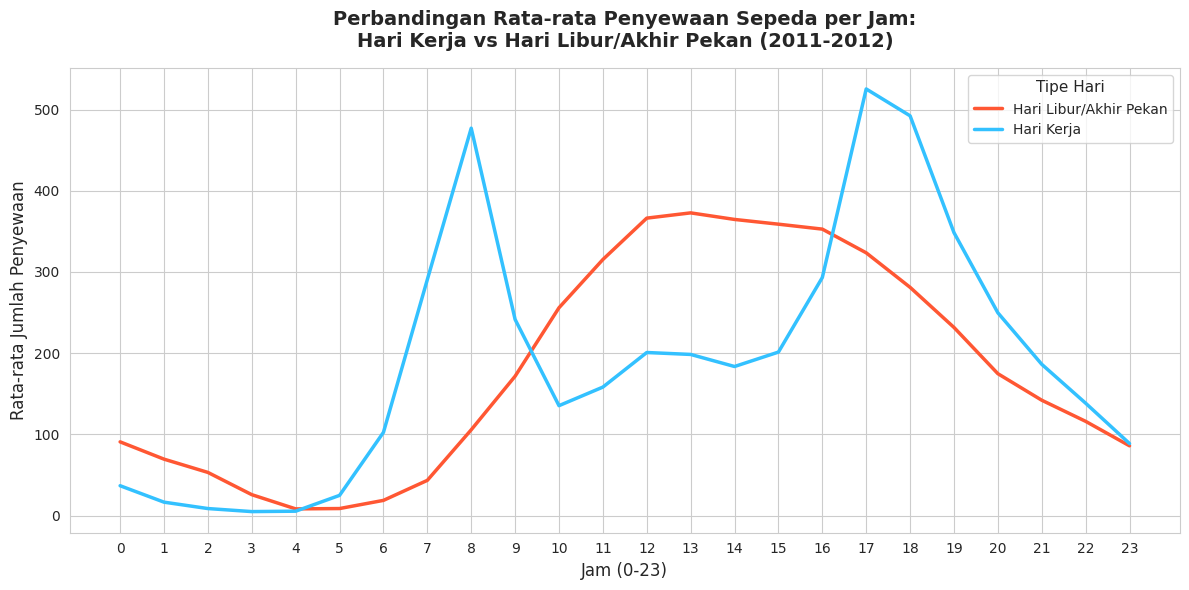

In [14]:
# Menyiapkan data visualisasi
p1_data = bike_clean.groupby(by=['workingday', 'hr'])['cnt'].mean().reset_index()
p1_data['Tipe Hari'] = p1_data['workingday'].map({0: 'Hari Libur/Akhir Pekan', 1: 'Hari Kerja'})

# Membuat Line Chart
plt.figure(figsize=(12, 6))
sns.lineplot(data=p1_data, x='hr', y='cnt', hue='Tipe Hari', palette=['#FF5733', '#33C1FF'], linewidth=2.5)

# Desain Grafik (Saran 2: Visualisasi Efektif)
plt.title('Perbandingan Rata-rata Penyewaan Sepeda per Jam:\nHari Kerja vs Hari Libur/Akhir Pekan (2011-2012)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Jam (0-23)', fontsize=12)
plt.ylabel('Rata-rata Jumlah Penyewaan', fontsize=12)
plt.xticks(np.arange(0, 24, 1))
plt.legend(title='Tipe Hari', title_fontsize='11', fontsize='10')
plt.tight_layout()
plt.show()

### Pertanyaan 2:

/tmp/ipykernel_1706/1873227759.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=p2_data, x='weather_label', y='cnt', palette='Blues_r')


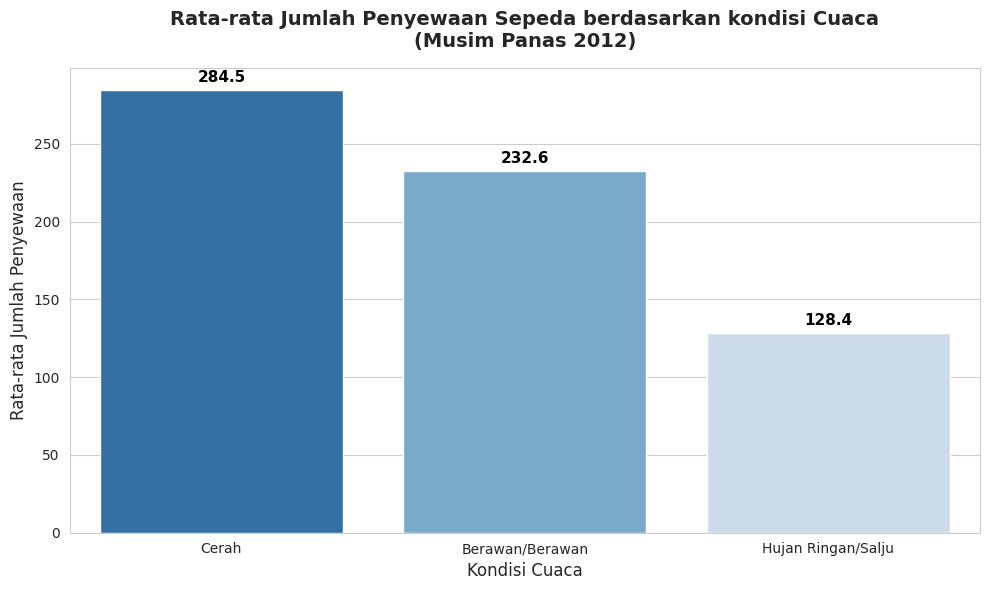

In [15]:
# Menyiapkan data visualisasi
p2_data = summer_2012.groupby(by='weather_label')['cnt'].mean().reset_index()

# Mengurutkan dari yang tertinggi ke terendah
p2_data = p2_data.sort_values(by='cnt', ascending=False)

# Membuat Bar Chart
plt.figure(figsize=(10, 6))
sns.barplot(data=p2_data, x='weather_label', y='cnt', palette='Blues_r')

# Desain Grafik (Saran 2: Visualisasi Efektif)
plt.title('Rata-rata Jumlah Penyewaan Sepeda berdasarkan kondisi Cuaca\n(Musim Panas 2012)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Kondisi Cuaca', fontsize=12)
plt.ylabel('Rata-rata Jumlah Penyewaan', fontsize=12)

# Menambahkan label angka di atas bar
for index, row in enumerate(p2_data['cnt']):
  plt.text(index, row + 5, round(row, 1), color='black', ha="center", fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- **Visualisasi di Pertanyaan 1** terdapat dua puncak *(bimodal)* pada hari kerja, yaitu sekitar pukul 08:00 dan 17:00-18:00, yang mengindikasikan penggunaan kurva lonceng *(bell curve)* dengan puncak di siang hingga sore hari (pukul 10:00-16:00).
- **Visualisasi di Pertanyaan 2** cuaca sangat mempengaruhi bisnis. Pada musim panas 2012, cuaca cerah memiliki rata-rata penyewaan > 300 sepeda/jam, sedangkan saat hujan ringan/salju turun drastis mendekati 100 sepeda/jam.

## Analisis Lanjutan (Opsional)

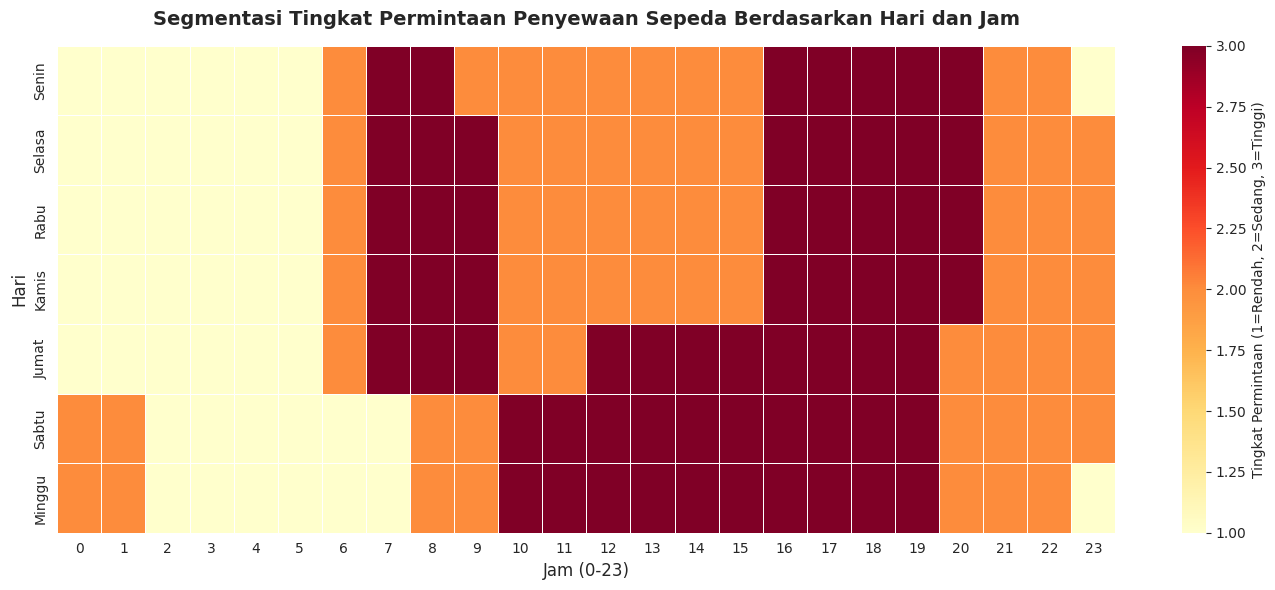

In [16]:
# ===========================================================================================================================================
# Untuk menjawab pertanyaan 3 : Bagaimana segmentasi tingkat permintaan penyewaan sepeda per jam berdasarkan jumlah penyewaan (cnt) ke dalam
# kategori Rendah, Sedang, dan Tinggi menggunakan metode binning selama 2011-2012, dan jam-jam mana yang masuk kategori Tinggi?
# ===========================================================================================================================================
# Tujuannya Menerapkan teknik Clustering manual (Binning) tanpa Machine Learning untuk menjawab Pertanyaan ke-3.
# Alasannya untuk menyederhanakan data penyewaan (cnt) yang kontinu menjadi kategori diskrit (Rendah, Sedang, Tinggi).
# Metodenya membagi data menjadi 3 bagian menggunakan pendekatan kuantil (33% & 66%).
# Outputnya membantu penentuan alokasi armada sepeda pada jam-jam sibuk.
# ===========================================================================================================================================


# Menambahkan .copy() untuk menghindari SettingWithCopyWarning
bike_clean = bike_clean.copy()

# Menentukan batas (threshold) menggunakan kuantil 33% dan 66%
q1 = bike_clean['cnt'].quantile(0.33)
q2 = bike_clean['cnt'].quantile(0.66)

# Menerapkan Binning dengan pd.cut
bike_clean['demand_category'] = pd.cut(
    bike_clean['cnt'],
    bins=[-1, q1, q2, bike_clean['cnt'].max()],
    labels=['Rendah', 'Sedang', 'Tinggi']
)

# Membuat Pivot Table (Heatmap) untuk melihat jam dan hari mana yang masuk kategori Tinggi
# 0 = Minggu, 1 = Senin, ... 6 = Sabtu
weekday_map = {0: 'Minggu', 1: 'Senin', 2: 'Selasa', 3: 'Rabu', 4: 'Kamis', 5: 'Jumat', 6: 'Sabtu'}
bike_clean['weekday_label'] = bike_clean['weekday'].map(weekday_map)

# Mengambil modus (kategori yang palin sering muncul) untuk setiap jam dan hari
pivot_binning = bike_clean.groupby(['weekday_label', 'hr'])['demand_category'].agg(lambda x: x.mode()[0]).unstack()

# Mengurutkan hari
day_order = ['Senin', 'Selasa', 'Rabu', 'Kamis', 'Jumat', 'Sabtu', 'Minggu']
pivot_binning = pivot_binning.reindex(day_order)

# Visualisasi Heatmap
plt.figure(figsize=(14, 6))

# Menggunakan .map() alih-alih .replace()
mapping_dict = {'Rendah': 1, 'Sedang': 2, 'Tinggi': 3}
heatmap_data = pivot_binning.apply(lambda col: col.map(mapping_dict)).astype(float)

sns.heatmap(heatmap_data, cmap='YlOrRd', cbar_kws={'label': 'Tingkat Permintaan (1=Rendah, 2=Sedang, 3=Tinggi)'}, linewidths=.5)
plt.title('Segmentasi Tingkat Permintaan Penyewaan Sepeda Berdasarkan Hari dan Jam', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Jam (0-23)', fontsize=12)
plt.ylabel('Hari', fontsize=12)
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Berdasarkan segmentasi *Binning*, tingkat permintaan **Tinggi** (warna oranye/merah tua) terknonsentrasi pada jam sibuk (pukul 07:00-09:00 dan 16:00-19:00) di hari kerja (Senin-Jumat). Pada hari Sabtu dan Minggu, kategori **Tinggi** bergeser ke siang hari (pukul 10:00-15:00).
- Membuktikan bahwa pola permintaan tidak seragam dan membutuhkan strategi distribusi yang berbeda antara hari kerja dan akhir pekan.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Terdapat perbedaan pola yang kontras antara hari kerja dan hari libur. Pada hari kerja, permintaan memuncak pada pukul 08:00 dan 17:00-18:00 (pola *commuting*). Pada hari libur, permintaan memuncak di siang hari (pukul 10:00-16:00).
- **Conclusion pertanyaan 2:** Cuaca memiliki dampak signifikan terhadap penyewaan. Pada musim panas 2012, cuaca cerah menghasilkan rata-rata penyewaan tertinggi (>300 unit/jam), sementara cuaca hujan ringan/salju menurunkan permintaan secara drastis hingga di bawah 100 unit/jam.
- **Conclusion pertanyaan 3 (Analisis Lanjutan):** Segmentasi *binning* mengonfirmasi bahwa kategori permintaan "Tinggi" terjadi pada jam sibuk di hari kerja dan siang hari di akhir pekan. Hal ini memvalidasi perlunya penyesuaian logistik berdasarkan waktu.

**Rekomendasi Action Item:**
- **Penyesuaian Distribusi (Berdasarkan Pertanyaan 1 & 3):** Tambah Ketersediaan sepeda di stasiun-stasiun area perkantoran/pemukiman pada jam 07:00-09:00 dan 16:00-19:00 di hari kerja. Untuk akhir pekan, alokasikan lebih banyak sepeda di area rekreasi/taman pada jam 10:00-16:00.
- **Strategi Mitigasi Cuaca (Berdasarkan Pertanyaan 2):** Saat prakiraan cuaca menunjukkan hujan ringan/lebat, tim operasional dapat menunda jadwal *maintenance* atau pengisian ulang *(rebalancing)* sepeda, dan mengalihkan fokus ke pengecekan kondisi sepeda di stasiun *indoor*.
- **Program Promosi** Memberikan insentif/diskon khusus pada jam-jam dengan kategori permintaan "Rendah" (misal: pukul 10:00-15:00 di hari kerja) untuk meratakan distribusi penggunaan.